In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats



In [2]:
data = {
    'Student':['A','B','C','D','E','F','G','H','I','J',
                'K','L','M','N','O','P','Q','R','S','T'],

    'Marks':[45, 50, 52, 48, 55, 60, 58, 62, 65, 59,
              61, 57, 63, 56, 54, 51, 49, 95, 100, 5]
}
df=pd.DataFrame(data)
print(df)
     

   Student  Marks
0        A     45
1        B     50
2        C     52
3        D     48
4        E     55
5        F     60
6        G     58
7        H     62
8        I     65
9        J     59
10       K     61
11       L     57
12       M     63
13       N     56
14       O     54
15       P     51
16       Q     49
17       R     95
18       S    100
19       T      5


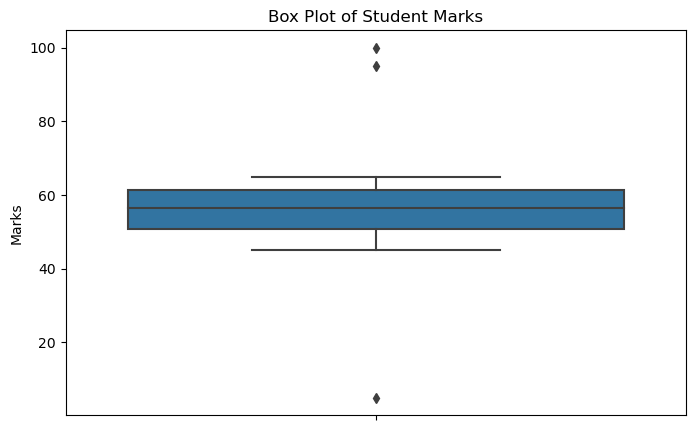

In [3]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])
plt.title("Box Plot of Student Marks")
plt.ylabel("Marks")
plt.show()

In [4]:
Q1 = df['Marks'].quantile(0.25)
Q3 = df['Marks'].quantile(0.75)
print("Q1 =", Q1)
print("Q3 =", Q3)

Q1 = 50.75
Q3 = 61.25


In [5]:
IQR=Q3-Q1
print("IQR=",IQR)

IQR= 10.5


In [6]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)
     

Lower Limit = 35.0
Upper Limit = 77.0


In [7]:
outliers_iqr = df[
    (df['Marks'] < lower_limit) |
    (df['Marks'] > upper_limit)
]
print("Outliers detected using IQR:")
print(outliers_iqr)

Outliers detected using IQR:
   Student  Marks
17       R     95
18       S    100
19       T      5


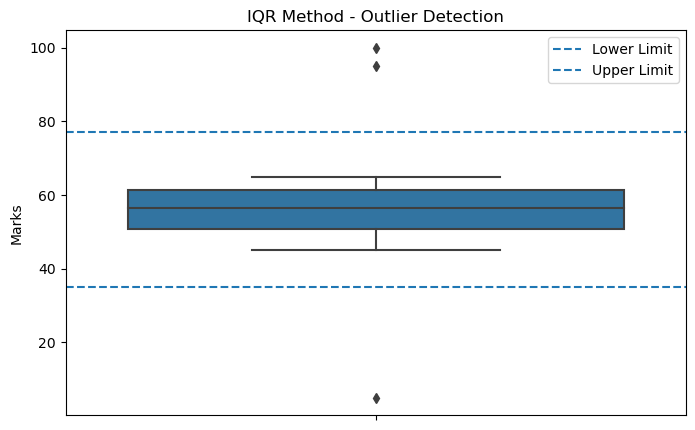

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])
plt.axhline(lower_limit, linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, linestyle='--', label='Upper Limit')
plt.title("IQR Method - Outlier Detection")
plt.legend()
plt.show()
     

In [9]:
df['Marks_IQR_Capped'] = df['Marks'].clip(lower=lower_limit,upper=upper_limit)
print(df[['Marks', 'Marks_IQR_Capped']])

    Marks  Marks_IQR_Capped
0      45              45.0
1      50              50.0
2      52              52.0
3      48              48.0
4      55              55.0
5      60              60.0
6      58              58.0
7      62              62.0
8      65              65.0
9      59              59.0
10     61              61.0
11     57              57.0
12     63              63.0
13     56              56.0
14     54              54.0
15     51              51.0
16     49              49.0
17     95              77.0
18    100              77.0
19      5              35.0


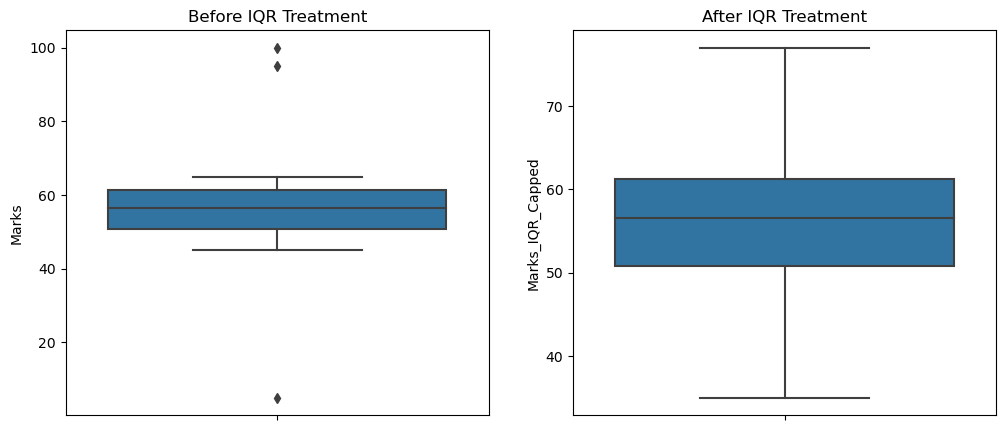

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=df['Marks'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")
sns.boxplot(y=df['Marks_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")
plt.show()

In [11]:
df['Z_Score']=stats.zscore(df['Marks'])
print(df[['Marks','Z_Score']])

    Marks   Z_Score
0      45 -0.676200
1      50 -0.400200
2      52 -0.289800
3      48 -0.510600
4      55 -0.124200
5      60  0.151800
6      58  0.041400
7      62  0.262200
8      65  0.427800
9      59  0.096600
10     61  0.207000
11     57 -0.013800
12     63  0.317400
13     56 -0.069000
14     54 -0.179400
15     51 -0.345000
16     49 -0.455400
17     95  2.083800
18    100  2.359799
19      5 -2.884199


In [12]:
z_outliers = df[abs(df['Z_Score']) > 3]
print("Outliers detected using Z-score:")
print(z_outliers)
df['Z_Outlier'] = abs(df['Z_Score']) > 3
print(df[['Marks', 'Z_Score', 'Z_Outlier']])

Outliers detected using Z-score:
Empty DataFrame
Columns: [Student, Marks, Marks_IQR_Capped, Z_Score]
Index: []
    Marks   Z_Score  Z_Outlier
0      45 -0.676200      False
1      50 -0.400200      False
2      52 -0.289800      False
3      48 -0.510600      False
4      55 -0.124200      False
5      60  0.151800      False
6      58  0.041400      False
7      62  0.262200      False
8      65  0.427800      False
9      59  0.096600      False
10     61  0.207000      False
11     57 -0.013800      False
12     63  0.317400      False
13     56 -0.069000      False
14     54 -0.179400      False
15     51 -0.345000      False
16     49 -0.455400      False
17     95  2.083800      False
18    100  2.359799      False
19      5 -2.884199      False


In [13]:
mean = df['Marks'].mean()
std = df['Marks'].std()
lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std
print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)
df['Marks_Z_Capped'] = df['Marks'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)
print(df[['Marks', 'Marks_Z_Capped']])

Lower Z-score limit = 1.4902946847626737
Upper Z-score limit = 113.00970531523733
    Marks  Marks_Z_Capped
0      45              45
1      50              50
2      52              52
3      48              48
4      55              55
5      60              60
6      58              58
7      62              62
8      65              65
9      59              59
10     61              61
11     57              57
12     63              63
13     56              56
14     54              54
15     51              51
16     49              49
17     95              95
18    100             100
19      5               5


    Marks  Marks_IQR_Capped  Marks_Z_Capped
0      45              45.0              45
1      50              50.0              50
2      52              52.0              52
3      48              48.0              48
4      55              55.0              55
5      60              60.0              60
6      58              58.0              58
7      62              62.0              62
8      65              65.0              65
9      59              59.0              59
10     61              61.0              61
11     57              57.0              57
12     63              63.0              63
13     56              56.0              56
14     54              54.0              54
15     51              51.0              51
16     49              49.0              49
17     95              77.0              95
18    100              77.0             100
19      5              35.0               5


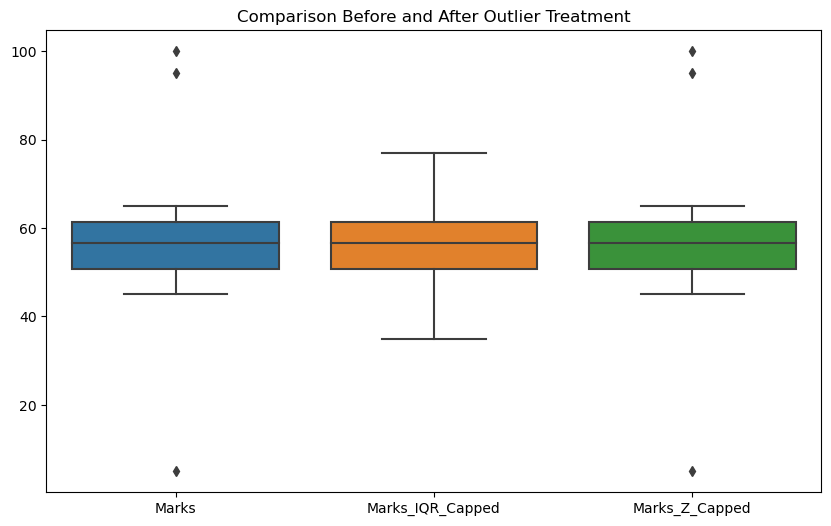

In [15]:
print(df[['Marks',
          'Marks_IQR_Capped',
          'Marks_Z_Capped']])
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[
    ['Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']
])
plt.title("Comparison Before and After Outlier Treatment")
plt.show()